# Step 3: Basket Analysis And Cross-Sell Rules

This notebook analyzes what customers buy together.

It includes:
- top product frequency analysis using chunked reads
- a manageable sampled transaction set for basket mining
- association rule generation for cross-sell ideas

Install `mlxtend` in your notebook environment if it is not already available.


In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

try:
    from mlxtend.frequent_patterns import apriori, association_rules
except ImportError as exc:
    raise ImportError("Install mlxtend first with `%pip install mlxtend`.") from exc


In [2]:
from pathlib import Path


def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in (current, current.parent):
        if (candidate / "orders.csv").exists() and (candidate / "products.csv").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root that contains the Instacart CSV files.")


PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "outputs"
ANALYSIS_DIR = OUTPUT_DIR / "analysis"
FIGURE_DIR = OUTPUT_DIR / "figures"
QUALITY_DIR = OUTPUT_DIR / "quality"

for path in (OUTPUT_DIR, ANALYSIS_DIR, FIGURE_DIR, QUALITY_DIR):
    path.mkdir(parents=True, exist_ok=True)


In [3]:
orders = pd.read_csv(PROJECT_ROOT / "orders.csv")
products = pd.read_csv(PROJECT_ROOT / "products.csv")

sample_order_ids = set(
    orders["order_id"].sample(n=8_000, random_state=42)
)

top_product_counts = None
sampled_order_products = []

for chunk in pd.read_csv(PROJECT_ROOT / "all_order_products.csv", chunksize=1_000_000):
    counts = chunk["product_id"].value_counts()
    top_product_counts = counts if top_product_counts is None else top_product_counts.add(counts, fill_value=0)

    sampled_chunk = chunk[chunk["order_id"].isin(sample_order_ids)]
    if not sampled_chunk.empty:
        sampled_order_products.append(sampled_chunk)

sampled_order_products = pd.concat(sampled_order_products, ignore_index=True)
top_products = (
    top_product_counts.sort_values(ascending=False)
    .head(25)
    .rename_axis("product_id")
    .reset_index(name="order_count")
    .merge(products, on="product_id", how="left")
)

top_products.head()


,product_id,order_count,product_name,aisle_id,department_id
0,24852,491291.0,Banana,24,4
1,13176,394930.0,Bag of Organic Bananas,24,4
2,21137,275577.0,Organic Strawberries,24,4
3,21903,251705.0,Organic Baby Spinach,123,4
4,47209,220877.0,Organic Hass Avocado,24,4


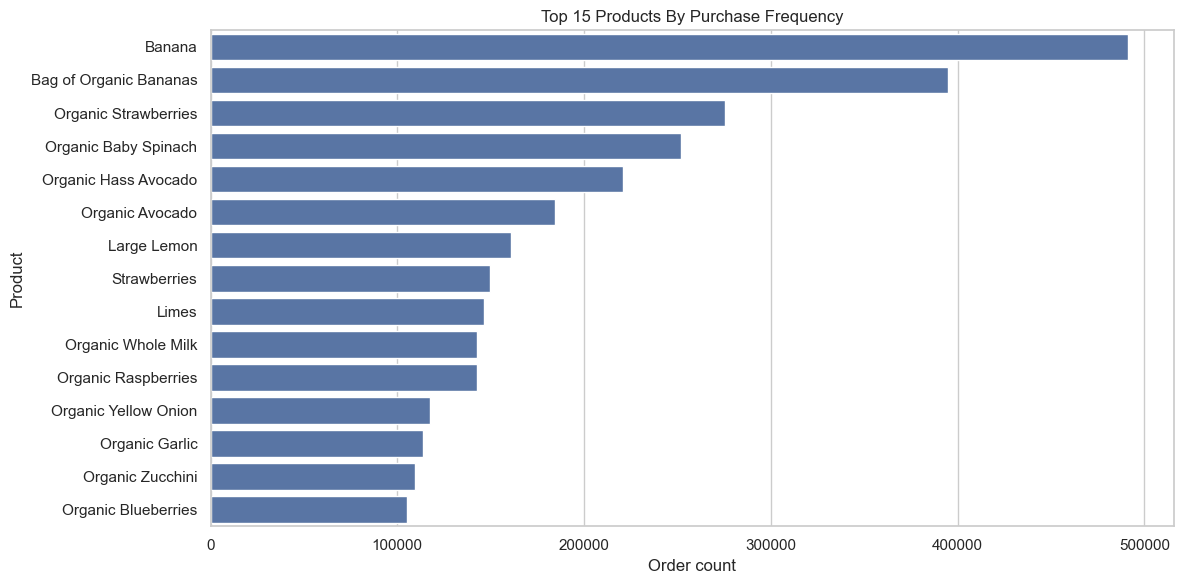

In [4]:
sns.barplot(
    data=top_products.head(15),
    y="product_name",
    x="order_count",
    orient="h",
)
plt.title("Top 15 Products By Purchase Frequency")
plt.xlabel("Order count")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_products.png", dpi=150, bbox_inches="tight")
plt.show()


In [5]:
analysis_products = set(top_products.head(20)["product_id"])

basket_sample = (
    sampled_order_products[sampled_order_products["product_id"].isin(analysis_products)]
    .merge(products[["product_id", "product_name"]], on="product_id", how="left")
)

basket_matrix = pd.crosstab(basket_sample["order_id"], basket_sample["product_name"]).astype(bool)

frequent_itemsets = apriori(basket_matrix, min_support=0.01, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.05)

rules = rules.sort_values(["lift", "confidence"], ascending=False)
rules["antecedents"] = rules["antecedents"].apply(lambda items: ", ".join(sorted(items)))
rules["consequents"] = rules["consequents"].apply(lambda items: ", ".join(sorted(items)))

rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]]
rules.head(15)


,antecedents,consequents,support,confidence,lift
56,Organic Garlic,Organic Yellow Onion,0.012603,0.199275,3.040691
57,Organic Yellow Onion,Organic Garlic,0.012603,0.192308,3.040691
21,Limes,Large Lemon,0.022456,0.237288,2.483274
20,Large Lemon,Limes,0.022456,0.235012,2.483274
72,"Bag of Organic Bananas, Organic Strawberries",Organic Hass Avocado,0.010082,0.275000,2.139216
77,Organic Hass Avocado,"Bag of Organic Bananas, Organic Strawberries",0.010082,0.078431,2.139216
34,Organic Lemon,Limes,0.011457,0.200803,2.121804
35,Limes,Organic Lemon,0.011457,0.121065,2.121804
60,Organic Lemon,Organic Hass Avocado,0.015353,0.269076,2.093135
61,Organic Hass Avocado,Organic Lemon,0.015353,0.119430,2.093135


In [6]:
top_products.to_csv(ANALYSIS_DIR / "top_products.csv", index=False)
rules.to_csv(ANALYSIS_DIR / "association_rules.csv", index=False)

rules.head(20)


,antecedents,consequents,support,confidence,lift
56,Organic Garlic,Organic Yellow Onion,0.012603,0.199275,3.040691
57,Organic Yellow Onion,Organic Garlic,0.012603,0.192308,3.040691
21,Limes,Large Lemon,0.022456,0.237288,2.483274
20,Large Lemon,Limes,0.022456,0.235012,2.483274
72,"Bag of Organic Bananas, Organic Strawberries",Organic Hass Avocado,0.010082,0.275000,2.139216
77,Organic Hass Avocado,"Bag of Organic Bananas, Organic Strawberries",0.010082,0.078431,2.139216
34,Organic Lemon,Limes,0.011457,0.200803,2.121804
35,Limes,Organic Lemon,0.011457,0.121065,2.121804
60,Organic Lemon,Organic Hass Avocado,0.015353,0.269076,2.093135
61,Organic Hass Avocado,Organic Lemon,0.015353,0.119430,2.093135


## Step 3 Outcome

After running this notebook you will have:
- a ranked list of the most frequently purchased products
- a sampled set of association rules for cross-sell opportunities
- outputs saved into `outputs/analysis/association_rules.csv`
